Exploring a graph.

In [1]:
import requests, readline, sys, json
import networkx as nx
import matplotlib as mpl
%matplotlib inline
%config InlineBacked.figure_format = 'svg'
import matplotlib.pyplot as plt
import matplotlib.cm as cmap
import seaborn
from graph_summary import *

vertexQ is a query to get all vertex labels:

In [2]:
vertexQ

'g.V().label().groupCount()'

getQuery gets the query results, and printResp prints a response

In [3]:
printResp(getQuery(vertexQ))


{'Event': '742490', 'FileObject': '349962', 'Principal': '10', 'Subject': '7395', 'NetFlowObject': '7596'}


getGroupCountQuery runs a query and converts the resulting dictionary to a groupCount

In [4]:
getGroupCountQuery(vertexQ)

{'Event': 742490,
 'FileObject': 349962,
 'NetFlowObject': 7596,
 'Principal': 10,
 'Subject': 7395}

getVertices collects the counts and number of incoming and outgoing edge labels for each vertex label.  For example:

In [5]:
vertices = getVertices()
print (vertices)

Vertex types/counts:
{'Event': {'count': 742490, 'in': {'EDGE_FILE_AFFECTS_EVENT': 391342}, 'out': {'EDGE_EVENT_AFFECTS_SUBJECT': 7274, 'EDGE_EVENT_AFFECTS_NETFLOW': 7596, 'EDGE_EVENT_ISGENERATEDBY_SUBJECT': 742490, 'EDGE_EVENT_AFFECTS_FILE': 279175}}, 'FileObject': {'count': 349962, 'in': {'EDGE_OBJECT_PREV_VERSION': 276283, 'EDGE_EVENT_AFFECTS_FILE': 279175}, 'out': {'EDGE_FILE_AFFECTS_EVENT': 391342, 'EDGE_OBJECT_PREV_VERSION': 276283}}, 'Principal': {'count': 10, 'in': {'EDGE_SUBJECT_HASLOCALPRINCIPAL': 7576}, 'out': {}}, 'Subject': {'count': 7395, 'in': {'child_of': 7385, 'EDGE_EVENT_AFFECTS_SUBJECT': 7274, 'EDGE_EVENT_ISGENERATEDBY_SUBJECT': 742490, 'EDGE_SUBJECT_HASPARENT_SUBJECT': 7274}, 'out': {'child_of': 7385, 'EDGE_SUBJECT_HASLOCALPRINCIPAL': 7576, 'EDGE_SUBJECT_HASPARENT_SUBJECT': 7274}}, 'NetFlowObject': {'count': 7596, 'in': {'EDGE_EVENT_AFFECTS_NETFLOW': 7596}, 'out': {}}}


Likewise, getEdges collects the counts of edge labels and the number of vertex labels on the source and target of each edge.

In [6]:
edges = getEdges()
print (edges)

Edge types/counts:
{'child_of': {'count': 7385, 'in': {'Subject': 7385}, 'out': {'Subject': 7385}}, 'EDGE_SUBJECT_HASLOCALPRINCIPAL': {'count': 7576, 'in': {'Principal': 7576}, 'out': {'Subject': 7576}}, 'EDGE_EVENT_AFFECTS_SUBJECT': {'count': 7274, 'in': {'Subject': 7274}, 'out': {'Event': 7274}}, 'EDGE_EVENT_AFFECTS_NETFLOW': {'count': 7596, 'in': {'NetFlowObject': 7596}, 'out': {'Event': 7596}}, 'EDGE_FILE_AFFECTS_EVENT': {'count': 391342, 'in': {'Event': 391342}, 'out': {'FileObject': 391342}}, 'EDGE_EVENT_ISGENERATEDBY_SUBJECT': {'count': 742490, 'in': {'Subject': 742490}, 'out': {'Event': 742490}}, 'EDGE_OBJECT_PREV_VERSION': {'count': 276283, 'in': {'FileObject': 276283}, 'out': {'FileObject': 276283}}, 'EDGE_SUBJECT_HASPARENT_SUBJECT': {'count': 7274, 'in': {'Subject': 7274}, 'out': {'Subject': 7274}}, 'EDGE_EVENT_AFFECTS_FILE': {'count': 279175, 'in': {'FileObject': 279175}, 'out': {'Event': 279175}}}


Hmm.  Not very readable.  Let's try to do better.  printSummary takes a dictionary in one of the above forms and prints out the results in a more structured way.

In [7]:
printSummary(vertices)

{EDGE_FILE_AFFECTS_EVENT[391342]}
 -> 
Event[742490]
 -> 
{EDGE_EVENT_AFFECTS_SUBJECT[7274],
EDGE_EVENT_AFFECTS_NETFLOW[7596],
EDGE_EVENT_ISGENERATEDBY_SUBJECT[742490],
EDGE_EVENT_AFFECTS_FILE[279175]}

{EDGE_OBJECT_PREV_VERSION[276283],
EDGE_EVENT_AFFECTS_FILE[279175]}
 -> 
FileObject[349962]
 -> 
{EDGE_FILE_AFFECTS_EVENT[391342],
EDGE_OBJECT_PREV_VERSION[276283]}

{EDGE_SUBJECT_HASLOCALPRINCIPAL[7576]}
 -> 
Principal[10]
 -> 
{}

{child_of[7385],
EDGE_EVENT_AFFECTS_SUBJECT[7274],
EDGE_EVENT_ISGENERATEDBY_SUBJECT[742490],
EDGE_SUBJECT_HASPARENT_SUBJECT[7274]}
 -> 
Subject[7395]
 -> 
{child_of[7385],
EDGE_SUBJECT_HASLOCALPRINCIPAL[7576],
EDGE_SUBJECT_HASPARENT_SUBJECT[7274]}

{EDGE_EVENT_AFFECTS_NETFLOW[7596]}
 -> 
NetFlowObject[7596]
 -> 
{}



How about for edges?

In [9]:
printSummary(edges)

{Subject[7385]}
 -> 
child_of[7385]
 -> 
{Subject[7385]}

{Principal[7576]}
 -> 
EDGE_SUBJECT_HASLOCALPRINCIPAL[7576]
 -> 
{Subject[7576]}

{Subject[7274]}
 -> 
EDGE_EVENT_AFFECTS_SUBJECT[7274]
 -> 
{Event[7274]}

{NetFlowObject[7596]}
 -> 
EDGE_EVENT_AFFECTS_NETFLOW[7596]
 -> 
{Event[7596]}

{Event[391342]}
 -> 
EDGE_FILE_AFFECTS_EVENT[391342]
 -> 
{FileObject[391342]}

{Subject[742490]}
 -> 
EDGE_EVENT_ISGENERATEDBY_SUBJECT[742490]
 -> 
{Event[742490]}

{FileObject[276283]}
 -> 
EDGE_OBJECT_PREV_VERSION[276283]
 -> 
{FileObject[276283]}

{Subject[7274]}
 -> 
EDGE_SUBJECT_HASPARENT_SUBJECT[7274]
 -> 
{Subject[7274]}

{FileObject[279175]}
 -> 
EDGE_EVENT_AFFECTS_FILE[279175]
 -> 
{Event[279175]}



Now let's build and visualize a (bipartite) graph.  Nodes will represent either node or edge labels, and edges represent that a node can have an in-edge or out-edge with a given label (or vice versa).

In [10]:
G = nx.DiGraph()


In [11]:
G.add_nodes_from(vertices,bipartite=0)
G.add_nodes_from(edges,bipartite=1)

In [12]:
for v in vertices.keys():
    for e in vertices[v]['in'].keys():
        G.add_edge(e,v)
    for e in vertices[v]['out'].keys():
        G.add_edge(v,e)

In [36]:
nx.is_bipartite(G)

True

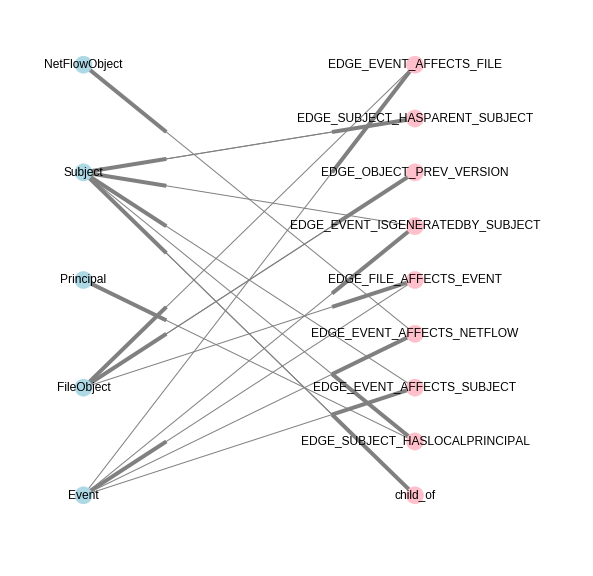

In [46]:
colors = ['lightblue' for x in vertices.keys()] + ['pink' for x in edges.keys()]
positions = {}
i = 1
for x in vertices.keys():
    positions[x] = (1,2*i-1)
    i = i + 1
i = 1
for x in edges.keys():
    positions[x] = (7,i)
    i = i + 1
fig = plt.figure(figsize=(10,10))
plt.gca().set_axis_off()   
plt.gca().set_xlim([-0.05, 10.05])    # add a little space around the plot
plt.gca().set_ylim([-0.05, 10.05])

nx.draw_networkx(G,pos=positions,
               with_labels=True,node_color=colors,edge_color='gray')

_ = plt.show()